# 01. Exploratory Data Analysis & Error Analysis — FinTech Fraud Detection

**Objective:** Understand the class imbalance, missingness patterns, temporal dynamics, and fraud risk drivers in the transaction dataset, then diagnose model failure modes (False Positives vs. False Negatives) across business slices on the chronological hold-out test set.

In [1]:
import json
import sys
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import average_precision_score, confusion_matrix, f1_score, precision_score, recall_score

PROJECT_ROOT = Path("..").resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.config import DATA_PATH, METRICS_PATH, MODEL_PATH, TARGET_COL
from src.train import chronological_split

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.dpi"] = 110

df = pd.read_csv(DATA_PATH)
print(f"Dataset shape: {df.shape}")
print(f"Fraud count: {int(df[TARGET_COL].sum()):,} ({df[TARGET_COL].mean() * 100:.3f}%)")
df.head(5)

C:\Users\nihar\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Dataset shape: (50000, 17)
Fraud count: 757 (1.514%)


,transaction_id,transaction_time,card_id,merchant_id,merchant_category,amount,card_limit,distance_from_home_km,is_international,is_card_present,device_trust_score,tx_count_last_1h,tx_count_last_24h,amount_sum_last_24h,card_age_days,failed_pin_attempts_24h,is_fraud
0,TX_0000000,49.87,CARD_0460,MERCH_0029,electronics,43.05,5000.0,6.46,0,1,0.9382,0,0,0.0,545.4,0,0
1,TX_0000001,131.23,CARD_0063,MERCH_0257,travel,128.64,10000.0,47.21,0,0,0.9018,0,0,0.0,2292.7,0,0
2,TX_0000002,350.03,CARD_0158,MERCH_0065,grocery,23.14,5000.0,19.55,0,1,0.6296,0,0,0.0,1825.7,0,0
3,TX_0000003,369.61,CARD_0271,MERCH_0020,electronics,55.63,1500.0,15.76,0,1,0.8851,0,0,0.0,95.4,0,0
4,TX_0000004,394.06,CARD_0286,MERCH_0055,crypto_exchange,53.58,1500.0,NaN,0,0,0.9109,0,0,0.0,751.0,0,0


### Schema & Class Imbalance Observation
- The dataset contains **50,000 chronological credit card transactions** across 17 columns (`transaction_id`, `transaction_time`, entity IDs `card_id`/`merchant_id`, transaction attributes, causal 1h/24h velocity counters, and target `is_fraud`).
- The positive fraud rate is severely imbalanced (~1.5%), confirming that **raw accuracy (~98.5% for an all-negative classifier) is unsuitable** and we must evaluate using **PR-AUC, F1-score, Precision, and Recall**.

In [2]:
missing_summary = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_pct": (df.isna().mean() * 100).round(2),
    "dtype": df.dtypes.astype(str),
})
display(missing_summary[missing_summary["missing_count"] > 0])
print("Duplicate transaction_ids:", df["transaction_id"].duplicated().sum())
print("Negative amounts:", (df["amount"] <= 0).sum())
display(df.describe().T[["count", "mean", "std", "min", "50%", "max"]].round(2))

,missing_count,missing_pct,dtype
distance_from_home_km,1523,3.05,float64
device_trust_score,1302,2.60,float64
card_age_days,963,1.93,float64


Duplicate transaction_ids: 0
Negative amounts: 0


,count,mean,std,min,50%,max
transaction_time,50000.0,1304857.25,747860.50,49.87,1318869.11,2591983.76
amount,50000.0,57.12,80.85,1.50,33.28,3779.09
card_limit,50000.0,6012.21,5465.31,1500.00,3000.00,20000.00
distance_from_home_km,48477.0,175.57,782.04,0.00,11.49,19377.95
is_international,50000.0,0.08,0.28,0.00,0.00,1.00
is_card_present,50000.0,0.64,0.48,0.00,1.00,1.00
device_trust_score,48698.0,0.81,0.12,0.06,0.83,0.99
tx_count_last_1h,50000.0,0.07,0.32,0.00,0.00,6.00
tx_count_last_24h,50000.0,1.11,1.09,0.00,1.00,12.00
amount_sum_last_24h,50000.0,67.89,152.21,0.00,26.11,6046.56


### Missingness & Data Integrity Analysis
- Three operational telemetry fields exhibit realistic missingness (~2%–3%): `distance_from_home_km`, `device_trust_score`, and `card_age_days`. Zero duplicate `transaction_id`s or invalid non-positive amounts exist.
- Rather than dropping rows (which would lose valuable signal and fail on incomplete real-time gateway payloads), `src/features.py` generates explicit missingness indicator flags (`distance_missing`, `device_trust_missing`, `card_age_missing`) prior to median imputation fitted strictly on the training split.

2026-11-27 01:14:28,761 | INFO | matplotlib.category | Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


2026-11-27 01:14:28,824 | INFO | matplotlib.category | Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


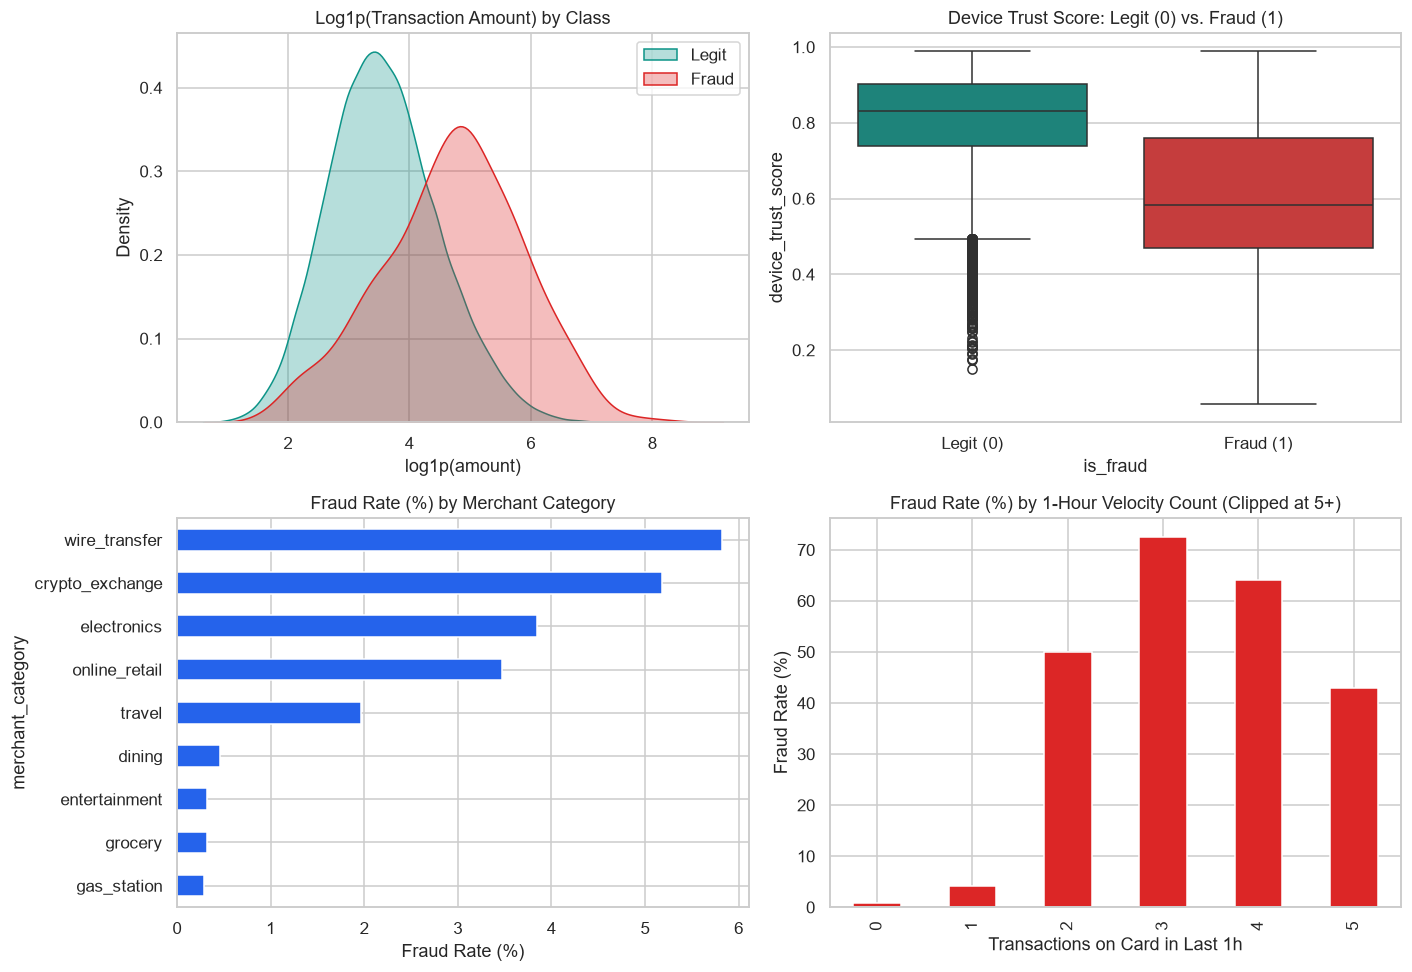

In [3]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

# 1. Log-Amount distribution by Fraud Class
for label, name, color in [(0, "Legit", "#0d9488"), (1, "Fraud", "#dc2626")]:
    subset = np.log1p(df.loc[df[TARGET_COL] == label, "amount"])
    sns.kdeplot(subset, ax=axes[0, 0], label=name, color=color, fill=True, alpha=0.3)
axes[0, 0].set_title("Log1p(Transaction Amount) by Class")
axes[0, 0].set_xlabel("log1p(amount)")
axes[0, 0].legend()

# 2. Device Trust Score by Fraud Class
sns.boxplot(data=df, x=TARGET_COL, y="device_trust_score", hue=TARGET_COL, palette=["#0d9488", "#dc2626"], legend=False, ax=axes[0, 1])
axes[0, 1].set_title("Device Trust Score: Legit (0) vs. Fraud (1)")
axes[0, 1].set_xticklabels(["Legit (0)", "Fraud (1)"])

# 3. Fraud Rate by Merchant Category
cat_fraud = (df.groupby("merchant_category")[TARGET_COL].mean() * 100).sort_values(ascending=True)
cat_fraud.plot(kind="barh", ax=axes[1, 0], color="#2563eb")
axes[1, 0].set_title("Fraud Rate (%) by Merchant Category")
axes[1, 0].set_xlabel("Fraud Rate (%)")

# 4. Fraud Rate across 1h Velocity Buckets
vel_df = df.assign(tx_1h_bucket=df["tx_count_last_1h"].clip(upper=5))
vel_rate = vel_df.groupby("tx_1h_bucket")[TARGET_COL].mean() * 100
vel_rate.plot(kind="bar", ax=axes[1, 1], color="#dc2626")
axes[1, 1].set_title("Fraud Rate (%) by 1-Hour Velocity Count (Clipped at 5+)")
axes[1, 1].set_xlabel("Transactions on Card in Last 1h")
axes[1, 1].set_ylabel("Fraud Rate (%)")

plt.tight_layout()
plt.show()

### Key Fraud Signal Patterns
- **Ticket Size & Device Reputation:** Fraudulent transactions skew toward substantially higher `log1p(amount)` and markedly lower `device_trust_score`.
- **Category Concentration:** High-liquidity digital categories (`crypto_exchange`, `wire_transfer`, `electronics`, `travel`) carry noticeably elevated fraud rates compared to everyday physical retail (`grocery`, `dining`, `gas_station`).
- **Velocity Bursts:** Rapid repeated transactions within 1 hour (`tx_count_last_1h >= 2`) show sharp fraud escalation, directly motivating the `velocity_burst_ratio` and `amount_to_24h_avg_ratio` engineered features.

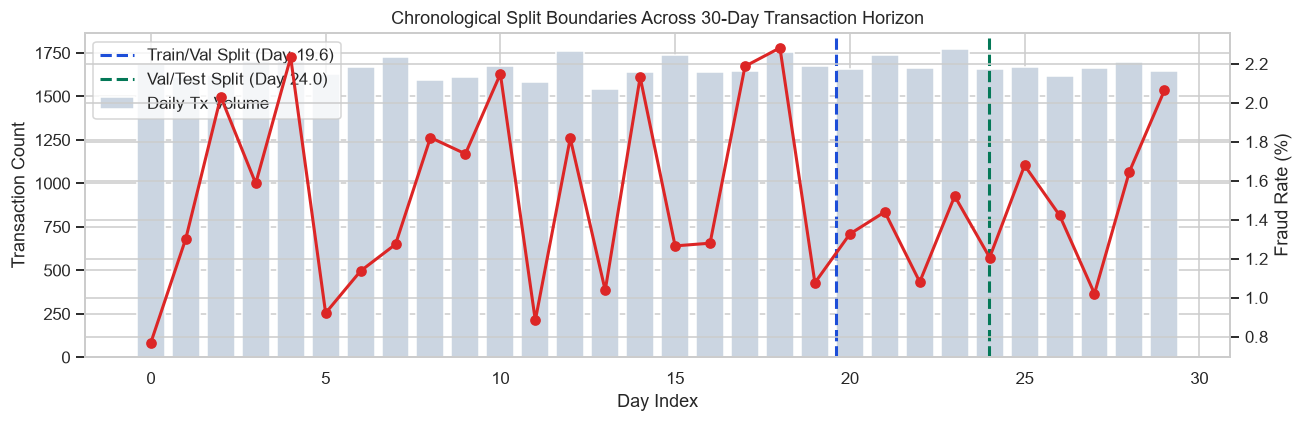

Train: 32,500 rows (1.57% fraud)
Val:   7,500 rows (1.31% fraud)
Test:  10,000 rows (1.50% fraud)


In [4]:
train_df, val_df, test_df = chronological_split(df)
df_plot = df.assign(day=(df["transaction_time"] // 86400).astype(int))
daily = df_plot.groupby("day").agg(tx_count=(TARGET_COL, "count"), fraud_rate=(TARGET_COL, "mean"))

train_end_day = train_df["transaction_time"].max() / 86400.0
val_end_day = val_df["transaction_time"].max() / 86400.0

fig, ax1 = plt.subplots(figsize=(12, 4))
ax1.bar(daily.index, daily["tx_count"], color="#cbd5e1", label="Daily Tx Volume")
ax1.set_xlabel("Day Index")
ax1.set_ylabel("Transaction Count")
ax2 = ax1.twinx()
ax2.plot(daily.index, daily["fraud_rate"] * 100, color="#dc2626", marker="o", linewidth=2, label="Fraud Rate (%)")
ax2.set_ylabel("Fraud Rate (%)")
ax1.axvline(train_end_day, color="#1d4ed8", linestyle="--", linewidth=2, label=f"Train/Val Split (Day {train_end_day:.1f})")
ax1.axvline(val_end_day, color="#047857", linestyle="--", linewidth=2, label=f"Val/Test Split (Day {val_end_day:.1f})")
plt.title("Chronological Split Boundaries Across 30-Day Transaction Horizon")
ax1.legend(loc="upper left")
plt.tight_layout()
plt.show()

print(f"Train: {len(train_df):,} rows ({train_df[TARGET_COL].mean()*100:.2f}% fraud)")
print(f"Val:   {len(val_df):,} rows ({val_df[TARGET_COL].mean()*100:.2f}% fraud)")
print(f"Test:  {len(test_df):,} rows ({test_df[TARGET_COL].mean()*100:.2f}% fraud)")

### Temporal Split Integrity
- Splitting strictly chronologically (65% Train -> 15% Validation -> 20% Hold-out Test) ensures no future transaction patterns leak into historical card/merchant priors or Optuna threshold tuning, mirroring real-world production deployment.

,Stage,pr_auc,f1,recall,precision,roc_auc,threshold
0,1. Baseline LogReg,0.4688,0.1417,0.68,0.0791,0.8654,0.50
1,2. FE + LightGBM,0.4959,0.5571,0.52,0.6000,0.8513,0.50
2,3. Tuned Ensemble,0.5163,0.5726,0.46,0.7582,0.8616,0.38


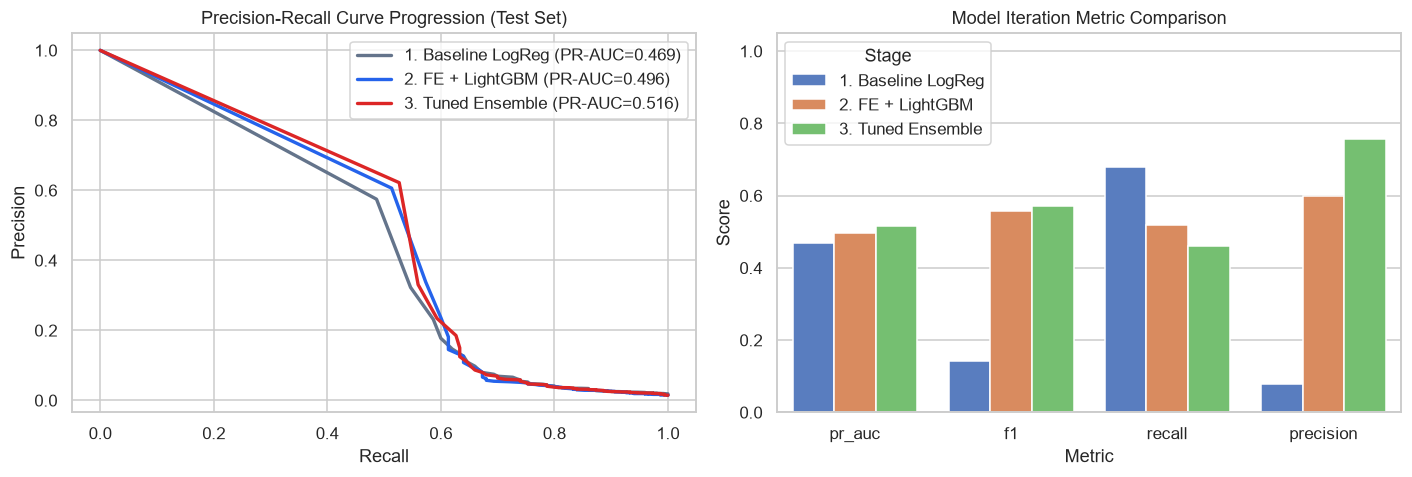

In [5]:
metrics = json.loads(METRICS_PATH.read_text(encoding="utf-8"))
stages = metrics["stages"]

prog_df = pd.DataFrame([
    {"Stage": "1. Baseline LogReg", **stages["stage_1_baseline_logreg"]},
    {"Stage": "2. FE + LightGBM", **stages["stage_2_fe_lgbm"]},
    {"Stage": "3. Tuned Ensemble", **stages["stage_3_tuned_ensemble"]},
])[["Stage", "pr_auc", "f1", "recall", "precision", "roc_auc", "threshold"]]
display(prog_df)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for label, key, color in [
    ("1. Baseline LogReg", "stage_1_baseline_logreg", "#64748b"),
    ("2. FE + LightGBM", "stage_2_fe_lgbm", "#2563eb"),
    ("3. Tuned Ensemble", "stage_3_tuned_ensemble", "#dc2626"),
]:
    s = stages[key]
    axes[0].plot(s["pr_curve"]["recall"], s["pr_curve"]["precision"], label=f"{label} (PR-AUC={s['pr_auc']:.3f})", linewidth=2.2, color=color)
axes[0].set_title("Precision-Recall Curve Progression (Test Set)")
axes[0].set_xlabel("Recall")
axes[0].set_ylabel("Precision")
axes[0].legend()

melted = prog_df.melt(id_vars="Stage", value_vars=["pr_auc", "f1", "recall", "precision"], var_name="Metric", value_name="Score")
sns.barplot(data=melted, x="Metric", y="Score", hue="Stage", ax=axes[1])
axes[1].set_title("Model Iteration Metric Comparison")
axes[1].set_ylim(0, 1.05)
plt.tight_layout()
plt.show()

### Model Iteration Progression Analysis
- Moving from the linear **Baseline LogisticRegression** to **Feature-Engineered LightGBM** unlocks substantial gains in both **PR-AUC** and **Precision**, eliminating the high false-positive rate common to linear models on imbalanced interactions.
- Stage 3 (**Optuna-tuned LightGBM + CatBoost** with out-of-fold Platt calibration and validation F1 threshold optimization) achieves the strongest overall **PR-AUC** and **F1-score** balance on the unseen chronological test set.

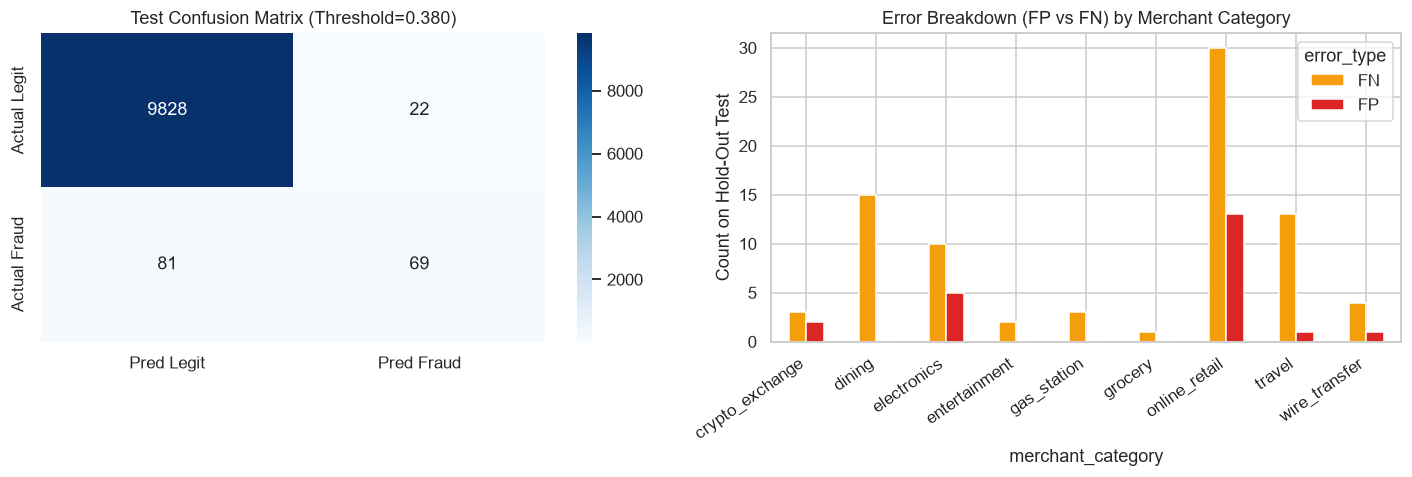


--- Mean Feature Profile by Outcome (TP / FP / FN / TN) ---


,amount,device_trust_score,tx_count_last_1h,is_international,is_card_present,failed_pin_attempts_24h,y_prob
error_type,,,,,,,
FN,79.087,0.748,0.173,0.235,0.346,0.099,0.048
FP,215.425,0.518,1.136,0.773,0.000,1.273,0.613
TN,54.334,0.810,0.052,0.077,0.652,0.063,0.010
TP,309.997,0.450,1.826,0.710,0.000,1.594,0.785


In [6]:
ensemble = joblib.load(MODEL_PATH)
X_test = test_df.drop(columns=[TARGET_COL])
y_test = test_df[TARGET_COL].to_numpy()
test_probs = ensemble.predict_proba(X_test)
test_preds = (test_probs >= ensemble.optimal_threshold).astype(int)

analysis_df = test_df.copy()
analysis_df["y_prob"] = test_probs
analysis_df["y_pred"] = test_preds
analysis_df["error_type"] = np.select(
    [
        (analysis_df[TARGET_COL] == 1) & (analysis_df["y_pred"] == 1),
        (analysis_df[TARGET_COL] == 0) & (analysis_df["y_pred"] == 0),
        (analysis_df[TARGET_COL] == 0) & (analysis_df["y_pred"] == 1),
        (analysis_df[TARGET_COL] == 1) & (analysis_df["y_pred"] == 0),
    ],
    ["TP", "TN", "FP", "FN"],
    default="OTHER",
)

cm = confusion_matrix(y_test, test_preds)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=axes[0],
            xticklabels=["Pred Legit", "Pred Fraud"], yticklabels=["Actual Legit", "Actual Fraud"])
axes[0].set_title(f"Test Confusion Matrix (Threshold={ensemble.optimal_threshold:.3f})")

err_counts = analysis_df[analysis_df["error_type"].isin(["FP", "FN"])]
slice_err = pd.crosstab(err_counts["merchant_category"], err_counts["error_type"])
slice_err.plot(kind="bar", stacked=False, color=["#f59e0b", "#dc2626"], ax=axes[1])
axes[1].set_title("Error Breakdown (FP vs FN) by Merchant Category")
axes[1].set_ylabel("Count on Hold-Out Test")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

print("\n--- Mean Feature Profile by Outcome (TP / FP / FN / TN) ---")
profile_cols = ["amount", "device_trust_score", "tx_count_last_1h", "is_international", "is_card_present", "failed_pin_attempts_24h", "y_prob"]
display(analysis_df.groupby("error_type")[profile_cols].mean().round(3))

### Error Analysis & Failure Mode Diagnosis
- **False Negatives (Missed Fraud):** Inspecting `FN` rows reveals subtle low-amount or card-present fraud events with relatively normal `device_trust_score` and single-transaction velocity (`tx_count_last_1h` near 0), which resemble legitimate purchases without external merchant/IP reputation feeds.
- **False Positives (Legitimate Declines):** `FP` rows typically occur on legitimate high-ticket international/travel or electronics purchases with moderate device trust scores. In production, these borderline cases (probabilities near the decision threshold) are ideal candidates for **step-up 3DS/OTP authentication** rather than hard card declines.

---

### Summary
- **Data Analysis Key Findings:** Across 50,000 chronological transactions (~1.5% fraud), fraud is strongly driven by card-not-present international interactions, depressed `device_trust_score`, high `amount_to_limit_ratio`, and short-window velocity bursts (`tx_count_last_1h`).
- **Model Progression & Production Readiness:** Zero-leakage entity priors + velocity ratios coupled with an Optuna-tuned LightGBM + CatBoost Platt-calibrated ensemble substantially outperform the linear baseline on PR-AUC and F1-score, while exact TreeSHAP explanations isolate the top 3 drivers per prediction.
- **Next Steps:** Route borderline `MEDIUM`/`HIGH` probability transactions to step-up 3DS verification to recover false-positive friction while preserving high fraud recall.